# Prépare l'environnement et importe les fonctions de lecture et de découpage.

In [25]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/home/abdelkarim/project/arxiv-bot")
sys.path.insert(0, str(PROJECT_ROOT))

from rag.src.chunking.bge_m3 import read_parquet_file, chunk_article
from rag.src.chunking.openrouter import read_parquet_file, chunk_article

# Définit le dossier contenant les métadonnées produites par l'ingestion.

In [3]:
PROJECT_ROOT = Path("/home/abdelkarim/project/arxiv-bot")
OUTPUT_DIR = PROJECT_ROOT / "data" / "metadata"

# Charge les métadonnées des articles depuis le fichier Parquet.

In [6]:
metadata = list(read_parquet_file(OUTPUT_DIR/ "batch_00000.parquet"))

# Affiche le nombre total d'articles disponibles pour l'analyse.

In [10]:
print(f"Nombre d'articles : {len(metadata):,}")

Nombre d'articles : 1,000


# Découpe chaque article en chunks et rassemble tous les résultats.

In [14]:
all_chunks = []

for article in metadata:
    chunks = chunk_article(article)
    all_chunks.extend(chunks)

print(f"Nombre total de chunks : {len(all_chunks):,}")

Nombre total de chunks : 26,227


# Convertit les chunks en DataFrame pour faciliter leur exploration.

In [20]:
chunks_df = pd.DataFrame(all_chunks)

# Affiche un aperçu des premiers chunks et de leurs colonnes.

In [21]:
chunks_df.head()

,chunk_id,article_id,title,source,section,subsection,text,token_count
0,0,2608.27424,Beyond F1: Evaluating Coverage and Failure Rec...,http://arxiv.org/abs/2608.27424v1,abstract,NaN,Static scanners are increasingly used to ident...,210
1,1,2608.27424,Beyond F1: Evaluating Coverage and Failure Rec...,http://arxiv.org/abs/2608.27424v1,introduction,NaN,Model distribution creates a critical security...,323
2,2,2608.27424,Beyond F1: Evaluating Coverage and Failure Rec...,http://arxiv.org/abs/2608.27424v1,introduction,NaN,Figure 1 summarizes the benchmark’s three anal...,232
3,3,2608.27424,Beyond F1: Evaluating Coverage and Failure Rec...,http://arxiv.org/abs/2608.27424v1,methodology,NaN,4.1\nCorpus and Experimental Conditions\n\nThe...,347
4,4,2608.27424,Beyond F1: Evaluating Coverage and Failure Rec...,http://arxiv.org/abs/2608.27424v1,methodology,NaN,Ground truth is assigned at the specimen-famil...,359


# Calcule le nombre de chunks générés pour chaque article.

In [23]:
chunks_article = (chunks_df.groupby("article_id").size())
chunks_article.describe()

count    999.000000
mean      26.253253
std       18.423076
min        2.000000
25%       17.000000
50%       22.000000
75%       31.000000
max      366.000000
dtype: float64

# Trace l'histogramme du nombre de chunks par article.

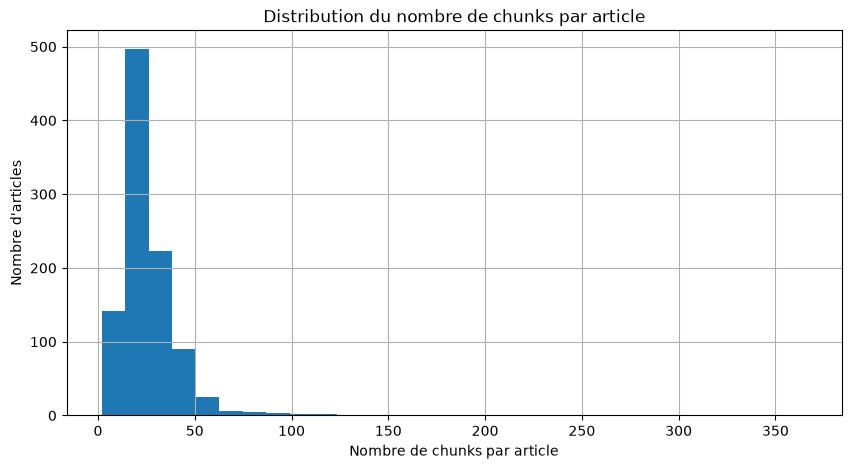

In [42]:
plt.figure(figsize=(10, 5))

plt.hist(
    chunks_article,
    bins=30
)

plt.xlabel("Nombre de chunks par article")
plt.ylabel("Nombre d'articles")
plt.title("Distribution du nombre de chunks par article")
plt.grid(True)

plt.show()

# Visualise la distribution du nombre de chunks par article sous forme d'histogramme.

/tmp/ipykernel_11115/1485397989.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(chunks_article, vert=False)


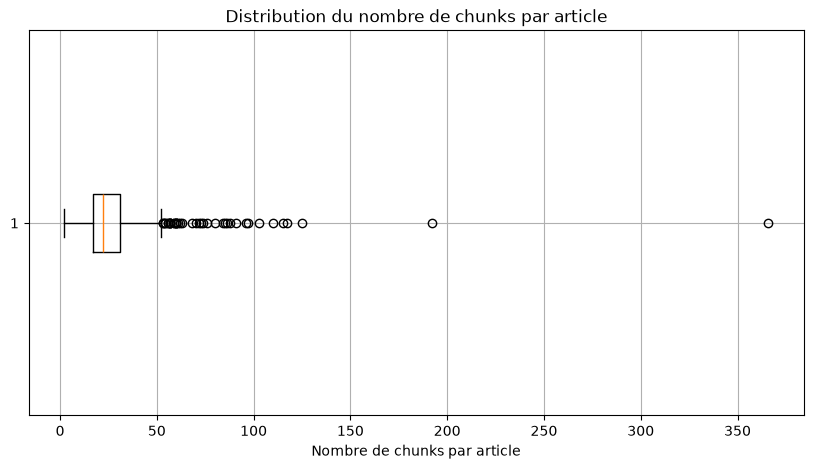

In [40]:
plt.figure(figsize=(10, 5))

plt.boxplot(chunks_article, vert=False)

plt.xlabel("Nombre de chunks par article")
plt.title("Distribution du nombre de chunks par article")

plt.grid(True)
plt.show()

# Compare la distribution du nombre de chunks avec une boîte à moustaches.

In [43]:
chunks_df["token_count"].describe()

count    26227.000000
mean       319.024250
std        114.093689
min          1.000000
25%        261.000000
50%        354.000000
75%        397.000000
max       1000.000000
Name: token_count, dtype: float64

# Résume statistiquement le nombre de tokens par chunk.

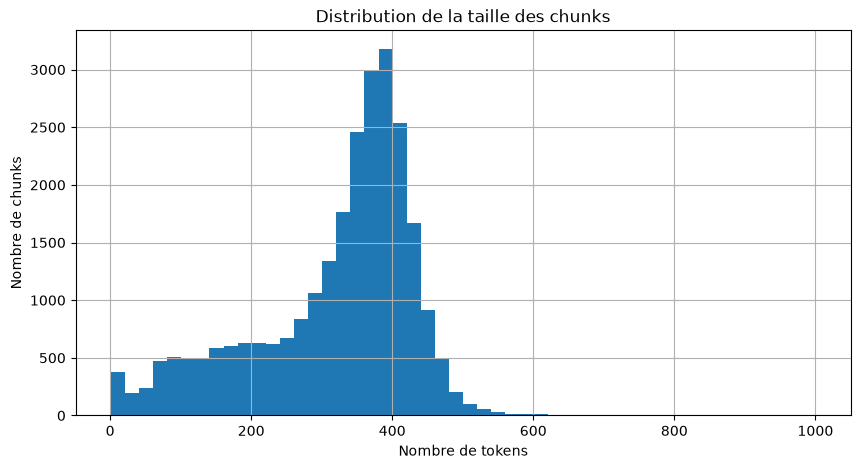

In [46]:
plt.figure(figsize=(10, 5))

plt.hist(
    chunks_df["token_count"],
    bins=50
)

plt.xlabel("Nombre de tokens")
plt.ylabel("Nombre de chunks")
plt.title("Distribution de la taille des chunks")

plt.grid(True)
plt.show()

# Visualise la distribution de la taille des chunks en tokens.

/tmp/ipykernel_11115/2281544157.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


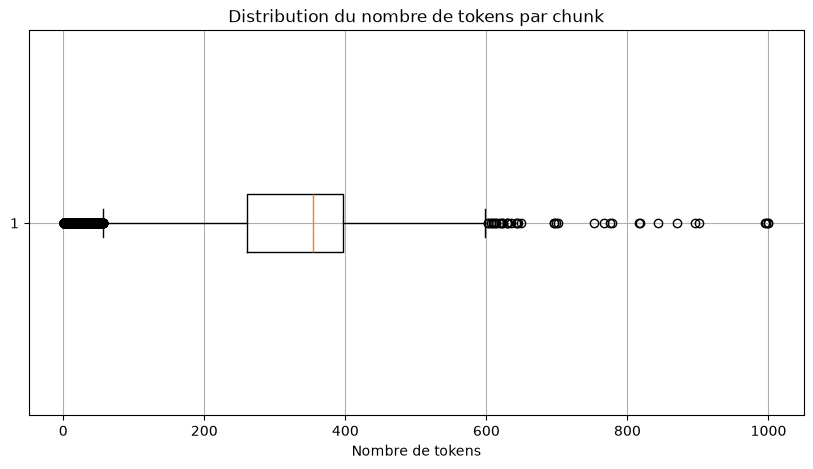

In [47]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    chunks_df["token_count"],
    vert=False
)

plt.xlabel("Nombre de tokens")
plt.title("Distribution du nombre de tokens par chunk")

plt.grid(True)
plt.show()

# Montre la distribution des tailles avec une boîte à moustaches.

In [48]:
short_chunks = chunks_df[
    chunks_df["token_count"] < 100
]

print(f"Chunks < 100 tokens : {len(short_chunks):,}")

print(
    f"Pourcentage : "
    f"{len(short_chunks) / len(chunks_df) * 100:.2f}%"
)

Chunks < 100 tokens : 1,761
Pourcentage : 6.71%


# Identifie et quantifie les chunks très courts.

In [49]:
short_chunks[
    [
        "article_id",
        "section",
        "subsection",
        "token_count",
        "text"
    ]
].head(10)

,article_id,section,subsection,token_count,text
9,2608.27424,results,NaN,91,5.9\nResearch-Question Answers\n\nThe precedin...
53,2608.27427,discussion,NaN,83,"PES is directional, like BLP, but the directio..."
66,2608.27454,methodology,experimental setup,83,4.2.1. Skill Evolution Across Models and Tasks...
79,2608.27421,abstract,NaN,75,Findings: In this two-site retrospective study...
153,2608.27397,conclusion,NaN,76,We introduced an SAE-guided ﬁne-tuning frame-\...
155,2608.27397,acknowledgment,NaN,60,J. Mu and G. Chen’s effort was partially suppo...
176,2608.27429,results,NaN,1,5.1
195,2608.27367,experiments,NaN,38,We design experiments to answer: RQ1: Does SCG...
214,2608.27449,experimental setup,NaN,39,Evaluation Setting.\nEach task is allowed up t...
225,2608.27439,introduction,NaN,18,"cross-harness transferability. Moreover, our r..."


# Inspecte quelques exemples de chunks courts avec leurs métadonnées.

In [51]:
large_chunks = chunks_df[
    chunks_df["token_count"] > 400
]

print(f"Chunks > 1000 tokens : {len(large_chunks):,}")

print(
    f"Pourcentage : "
    f"{len(large_chunks) / len(chunks_df) * 100:.2f}%"
)

Chunks > 1000 tokens : 6,076
Pourcentage : 23.17%


# Identifie et quantifie les chunks dépassant le seuil de taille choisi.

In [52]:
large_chunks[
    [
        "article_id",
        "section",
        "token_count"
    ]
].head(10)

,article_id,section,token_count
5,2608.27424,methodology,404
25,2608.27427,introduction,416
28,2608.27427,introduction,411
37,2608.27427,introduction,407
41,2608.27427,introduction,418
52,2608.27427,discussion,402
60,2608.27454,introduction,408
67,2608.27454,method,401
81,2608.27421,introduction,411
85,2608.27421,results,447


# Inspecte les premiers chunks volumineux et leurs sections.

In [53]:
section_counts = (
    chunks_df["section"]
    .fillna("unknown")
    .value_counts()
)

section_counts

section
introduction             4803
model                    4162
method                   3739
related work             3232
results                  1380
conclusion               1050
abstract                  981
experiments               892
experimental setup        882
methodology               875
evaluation                726
methods                   725
discussion                707
limitations               558
background                492
analysis                  313
result                    221
experiment                192
approach                   88
future work                88
acknowledgment             37
literature review          37
materials and methods      30
acknowledgement            12
limitation                  5
Name: count, dtype: int64

# Compte les chunks par section en remplaçant les sections absentes.

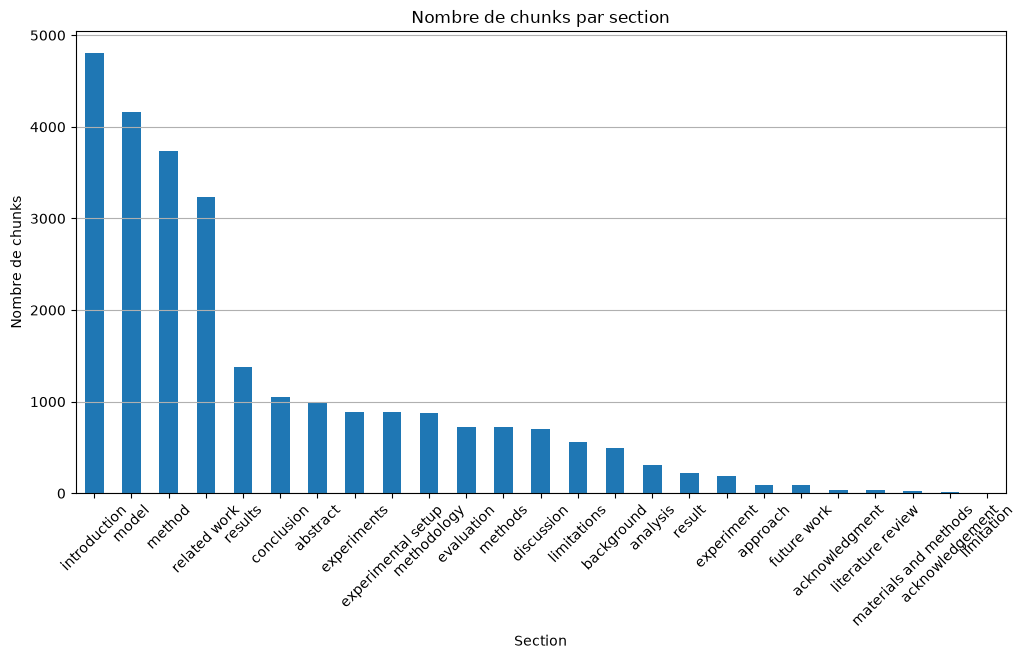

In [54]:
plt.figure(figsize=(12, 6))

section_counts.plot(kind="bar")

plt.xlabel("Section")
plt.ylabel("Nombre de chunks")
plt.title("Nombre de chunks par section")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

# Représente la répartition des chunks entre les différentes sections.

In [55]:
for i, row in chunks_df.head(5).iterrows():

    print("=" * 100)
    print(f"Chunk ID    : {row['chunk_id']}")
    print(f"Article ID  : {row['article_id']}")
    print(f"Section     : {row['section']}")
    print(f"Subsection  : {row['subsection']}")
    print(f"Token count : {row['token_count']}")
    print("-" * 100)
    print(row["text"])
    print()

Chunk ID    : 0
Article ID  : 2608.27424
Section     : abstract
Subsection  : nan
Token count : 210
----------------------------------------------------------------------------------------------------
Static scanners are increasingly used to identify executable or otherwise unsafe content in machine-
learning artifacts, yet conventional evaluation metrics characterize only cases where a scanner
yields a usable security judgment. We evaluate ModelScan, ModelAudit, and Fickling using a
controlled, artifact-backed benchmark on a synthetic corpus of 170 Pickle and PyTorch focused
artifacts across 145 specimen families, 135 of which have binary security ground truth and 10 of
which are intentionally malformed without labels. We explicitly distinguish non-N/A coverage,
analysis completion, definitive security decisions, non-security findings, and unsupported outcomes.
On labeled families, ModelAudit produced definitive security decisions for all 135 families (100%),
Fickling for 110 (81.5%),

# Affiche les informations et le texte de quelques chunks représentatifs.

In [56]:
article_id = metadata[0]["arxiv_id"]

article_chunks = (
    chunks_df[
        chunks_df["article_id"] == article_id
    ]
    .sort_values("chunk_id")
)

print(f"Article : {article_id}")
print(f"Nombre de chunks : {len(article_chunks)}")

Article : 2608.27424
Nombre de chunks : 15


# Sélectionne un article précis et trie ses chunks dans leur ordre d'origine.

In [57]:
for _, row in article_chunks.iterrows():

    print("=" * 100)
    print(
        f"Chunk {row['chunk_id']} | "
        f"Section: {row['section']} | "
        f"Tokens: {row['token_count']}"
    )
    print("-" * 100)
    print(row["text"])

Chunk 0 | Section: abstract | Tokens: 210
----------------------------------------------------------------------------------------------------
Static scanners are increasingly used to identify executable or otherwise unsafe content in machine-
learning artifacts, yet conventional evaluation metrics characterize only cases where a scanner
yields a usable security judgment. We evaluate ModelScan, ModelAudit, and Fickling using a
controlled, artifact-backed benchmark on a synthetic corpus of 170 Pickle and PyTorch focused
artifacts across 145 specimen families, 135 of which have binary security ground truth and 10 of
which are intentionally malformed without labels. We explicitly distinguish non-N/A coverage,
analysis completion, definitive security decisions, non-security findings, and unsupported outcomes.
On labeled families, ModelAudit produced definitive security decisions for all 135 families (100%),
Fickling for 110 (81.5%), and ModelScan for 67 (49.6%). Conditional on making a def